<a href="https://colab.research.google.com/github/rubendrt42-eng/SQL-Analitica-Ruben/blob/main/Etapa2_OT/Etapa2_Exploracion_OT_RubenRodriguez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Avance Reto Etapa 2 · Análisis y exploración de los datos

**Socio formador:** OT Consulting México
**Materia:** Soporte analítico para la toma de decisiones (TI2006B, Gpo 301)
**Alumno:** Rubén David Rodríguez Treviño · A01198984
**Fecha de corte de los datos:** 16 de noviembre de 2026

---

**¿Qué hay en este notebook?**

La exploración completa de las fuentes de datos que nos dio OT Consulting: archivo por archivo y columna por columna. Las respuestas y hallazgos van en las celdas de texto, justo debajo del código que los respalda.

1. Origen de los datos
2. Carga de los datos (evidencia de importación)
3. Exploración archivo por archivo
4. Integridad entre tablas (con SQL)
5. Resumen de errores, faltantes e inconsistencias
6. Modelo de datos sugerido con los errores marcados
7. ¿Qué se puede medir hoy y qué no?
8. Conclusiones de la exploración

## 1. Origen de los datos

**¿De dónde salen los datos?**
De la copia de la aplicación interna de recursos humanos de OT (*OTC Sandbox – HR Management*), que corre en Firebase (Firestore). Entramos con el usuario del equipo y extrajimos las 9 colecciones que guarda la app: colaboradores, usuarios, habilidades, roles, departamentos, matriz de habilidades, clientes, asignaciones y activos.

**¿Por qué hay 11 archivos y no 9?**
Porque la app guarda algunos datos *anidados* dentro de otros registros. Para poder analizarlos los "aplané" en tablas:

| Colección en la app | Archivo(s) para el análisis |
|---|---|
| clientes (con sus proyectos adentro) | `clientes.csv` + `proyectos.csv` |
| asignaciones (una lista de proyectos por colaborador) | `asignaciones.csv` (un renglón por colaborador-proyecto) |
| matriz de habilidades (un objeto por colaborador) | `matriz_habilidades.csv` (un renglón por colaborador-habilidad) |
| activos (con su historial de asignaciones adentro) | `activos.csv` + `activos_asignaciones.csv` |

**¿Los datos son reales?**
No. Son datos de ejemplo (todos los colaboradores se apellidan "PEREZ"). Por eso el valor de esta exploración está en la **estructura**: qué campos existen, cómo se relacionan y qué tan bien se capturan.

**¿Qué cuidé por privacidad?**
- Las contraseñas de los usuarios **no se extrajeron**.
- RFC, CURP, NSS, correo y teléfono se cambiaron por indicadores `1/0` (lleno o vacío), y de las ligas a documentos solo se dejó el conteo de documentos cargados. Domicilio, ficha médica y beneficiarios no se extrajeron. Así se puede medir qué tan completo está el expediente sin exponer el dato.

In [113]:
import os, zipfile, sqlite3, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 60)

CARPETA = 'datos_ot'

# En Google Colab: si no está la carpeta, pide subir datos_ot.zip (o los CSV sueltos)
if not os.path.isdir(CARPETA):
    from google.colab import files
    print('Sube el archivo datos_ot.zip')
    subidos = files.upload()
    os.makedirs(CARPETA, exist_ok=True)
    for nombre in subidos:
        if nombre.endswith('.zip'):
            zipfile.ZipFile(nombre).extractall('.')
        elif nombre.endswith('.csv'):
            os.replace(nombre, os.path.join(CARPETA, nombre))

FECHA_CORTE = pd.Timestamp('2026-11-16')   # día en que se extrajeron los datos
HORAS_MES = 176                            # 22 días x 8 horas (regla de OT)
CARGA_ADMIN = 0.20                         # 20% de costo administrativo (regla de OT)

# estilo de gráficas
AZUL, NARANJA, ROJO = '#2a78d6', '#eb6834', '#e34948'
TINTA, TINTA2, GRIS, FONDO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.edgecolor': GRIS, 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})
print('Listo. Archivos en la carpeta:', sorted(os.listdir(CARPETA)))

Listo. Archivos en la carpeta: ['activos.csv', 'activos_asignaciones.csv', 'asignaciones.csv', 'clientes.csv', 'colaboradores.csv', 'departamentos.csv', 'habilidades.csv', 'matriz_habilidades.csv', 'proyectos.csv', 'roles.csv', 'usuarios.csv']


## 2. Carga de los datos (evidencia de importación)

Cargo los 11 archivos. Las columnas de identificadores (`uid`, códigos) se leen como texto para que pandas no les cambie el formato.

In [114]:
IDS = ['uid', 'uid_colaborador', 'uid_cliente', 'uid_colab', 'codigo', 'id',
       'codigo_activo', 'codigo_habilidad']
ARCHIVOS = ['colaboradores', 'roles', 'departamentos', 'habilidades', 'matriz_habilidades',
            'clientes', 'proyectos', 'asignaciones', 'activos', 'activos_asignaciones', 'usuarios']

df = {}
for a in ARCHIVOS:
    t = pd.read_csv(f'{CARPETA}/{a}.csv', dtype=str)
    t = t.replace({'': np.nan})
    for c in t.columns:                      # numéricos donde sí aplica
        if c not in IDS:
            conv = pd.to_numeric(t[c], errors='coerce')
            if conv.notna().sum() == t[c].notna().sum() and t[c].notna().any():
                t[c] = conv
    df[a] = t

pd.DataFrame([{'archivo': f'{a}.csv', 'filas': d.shape[0], 'columnas': d.shape[1]}
              for a, d in df.items()])

,archivo,filas,columnas
0,colaboradores.csv,107,30
1,roles.csv,55,7
2,departamentos.csv,6,7
3,habilidades.csv,71,6
4,matriz_habilidades.csv,1539,3
5,clientes.csv,8,15
6,proyectos.csv,12,10
7,asignaciones.csv,31,7
8,activos.csv,123,13
9,activos_asignaciones.csv,91,5


**Resultado:** se importaron 11 archivos. La tabla más grande es la matriz de habilidades (1,539 renglones) y la central es colaboradores (107 personas).

Para no repetir código, armo una función que hace el perfil de cualquier tabla, columna por columna: tipo de dato, nulos, valores "de relleno" (como `PENDIENTE` o `1990-01-01`), cuántos valores distintos tiene y un ejemplo.

In [115]:
RELLENO = {'PENDIENTE', 'Pendiente', 'N/A', 'NA', '-', '1990-01-01', 'PENDIENTE LLAMAR', 'NO LO ENVIO'}

def perfil(tabla):
    filas = []
    for c in tabla.columns:
        s = tabla[c]
        txt = s.dropna().astype(str).str.strip()
        filas.append({
            'columna': c,
            'tipo': 'número' if pd.api.types.is_numeric_dtype(s) else 'texto',
            'nulos': int(s.isna().sum()),
            '% nulos': round(s.isna().mean() * 100, 1),
            'relleno': int(txt.isin(RELLENO).sum()),
            'distintos': int(s.nunique()),
            'con espacios extra': int((txt != s.dropna().astype(str)).sum()),
            'ejemplo': ', '.join(map(str, s.dropna().unique()[:3]))[:55],
        })
    return pd.DataFrame(filas)

def contar(serie):
    return serie.value_counts(dropna=False).rename_axis('valor').reset_index(name='registros')

## 3. Exploración archivo por archivo

### 3.1 `colaboradores.csv` · el expediente de cada persona

Es la tabla central: de aquí sale quién trabaja en OT, en qué puesto y cuánto cuesta.

In [116]:
col = df['colaboradores']
perfil(col)

,columna,tipo,nulos,% nulos,relleno,distintos,con espacios extra,ejemplo
0,id,texto,0,0.0,0,107,0,"OTC003, OTC004, OTC005"
1,uid,texto,0,0.0,0,107,0,"1791239419973892, 1791239420562128, 1791239420735164"
2,nombre,texto,0,0.0,0,107,0,"ABRAHAM PEREZ GIL, ADRIANA PEREZ NAVARRETE, ALBERTO PER"
3,genero,texto,0,0.0,0,2,0,"Masculino, Femenino"
4,ciudad,texto,0,0.0,0,25,0,"Monterrey, Toluca, Guadalajara"
5,estatus,texto,0,0.0,0,2,0,"Activo, Baja"
6,fechainc,texto,1,0.9,0,85,0,"2016-06-12, 2022-08-01, 2016-01-11"
7,fechabaja,texto,92,86.0,0,9,0,"2026-10-23, 2026-10-12, 2026-10-05"
8,nomina,texto,6,5.6,0,9,0,"XERES OT-SINDICATO, OTC-SINDICATO (SMR), SMR"
9,depto,texto,95,88.8,0,2,0,"Operaciones y Soporte, Ventas"


In [117]:
print('Estatus:'); display(contar(col['estatus']))
activos = col[col['estatus'] == 'Activo']
print(f"Activos: {len(activos)} | Bajas: {(col['estatus'] == 'Baja').sum()}")
print(f"Puesto en PENDIENTE: {(col['puesto'] == 'PENDIENTE').sum()} en total, {(activos['puesto'] == 'PENDIENTE').sum()} de los activos")
print(f"Departamento vacío: {col['depto'].isna().sum()} en total, {activos['depto'].isna().sum()} de los activos")
print(f"Activos sin puesto definido NI asignación: "
      f"{((activos['puesto'] == 'PENDIENTE') & ~activos['uid'].isin(df['asignaciones']['uid_colaborador'])).sum()}")

Estatus:


,valor,registros
0,Activo,75
1,Baja,32


Activos: 75 | Bajas: 32
Puesto en PENDIENTE: 48 en total, 29 de los activos
Departamento vacío: 95 en total, 64 de los activos
Activos sin puesto definido NI asignación: 15


In [118]:
# Fechas: ¿son coherentes con el estatus?
col['fechainc_d'] = pd.to_datetime(col['fechainc'], errors='coerce')
col['fechabaja_d'] = pd.to_datetime(col['fechabaja'], errors='coerce')
print('Sin fecha de ingreso:', col.loc[col['fechainc_d'].isna(), 'id'].tolist())
print('Bajas sin fecha de baja:', ((col['estatus'] == 'Baja') & col['fechabaja_d'].isna()).sum())
print('Activos con fecha de baja capturada:', col.loc[(col['estatus'] == 'Activo') & col['fechabaja_d'].notna(), ['id', 'fechabaja']].values.tolist())
antig = (FECHA_CORTE - col.loc[col['estatus'] == 'Activo', 'fechainc_d']).dt.days / 365.25
print('Antigüedad de activos (años):', antig.describe().round(1).to_dict())

# Huecos en el consecutivo de IDs
nums = sorted(int(x[3:]) for x in col['id'])
print('IDs que no existen dentro del consecutivo:', [f'OTC{n:03d}' for n in range(1, max(nums) + 1) if n not in nums])

Sin fecha de ingreso: ['OTC109']
Bajas sin fecha de baja: 18
Activos con fecha de baja capturada: [['OTC029', '2026-11-19']]
Antigüedad de activos (años): {'count': 74.0, 'mean': 5.7, 'std': 5.0, 'min': 0.1, '25%': 2.1, '50%': 3.9, '75%': 9.2, 'max': 23.6}
IDs que no existen dentro del consecutivo: ['OTC001', 'OTC002', 'OTC035']


In [119]:
# Sueldos: ¿las fórmulas de la app cuadran?
neto = col['sueldo_imss'] + col['sueldo_asimilados'] + col['sueldo_complementos']
integrado = col['sueldo_neto_total'] + col['comision_nomina'] + col['impuestos_imss']
print('Registros donde neto ≠ suma de componentes:', (abs(neto - col['sueldo_neto_total']) > 0.05).sum())
print('Registros donde integrado ≠ neto + comisión + impuestos:', (abs(integrado - col['sueldo_total_integrado']) > 0.05).sum())
print('Activos con costo integrado en 0:', activos.loc[activos['sueldo_total_integrado'] == 0, 'id'].tolist())
print('Bajas que todavía tienen sueldo capturado:', ((col['estatus'] == 'Baja') & (col['sueldo_total_integrado'] > 0)).sum())
activos[activos['sueldo_total_integrado'] > 0]['sueldo_total_integrado'].describe().round(0)

Registros donde neto ≠ suma de componentes: 0
Registros donde integrado ≠ neto + comisión + impuestos: 0
Activos con costo integrado en 0: ['OTC013', 'OTC043', 'OTC049', 'OTC073', 'OTC080']
Bajas que todavía tienen sueldo capturado: 12


,sueldo_total_integrado
count,70.0
mean,55984.0
std,25519.0
min,7450.0
25%,38111.0
50%,52652.0
75%,67042.0
max,135461.0


In [120]:
for c in ['nomina', 'sgmm', 'segvida', 'formato_rh', 'aviso_infonavit', 'genero']:
    print(f'\n{c}:', contar(col[c]).set_index('valor')['registros'].to_dict())
print('\nCiudades distintas:', col['ciudad'].nunique())
print(contar(col['ciudad']).head(8).set_index('valor')['registros'].to_dict())
print('\nPuestos "FAMILIAR COLABORADOR":', col.loc[col['puesto'] == 'FAMILIAR COLABORADOR', ['id', 'estatus', 'sueldo_total_integrado']].values.tolist())
print('\nIndicadores de expediente:', {c: int(col[c].sum()) for c in ['tiene_rfc', 'tiene_curp', 'tiene_nss', 'tiene_email', 'tiene_telefono']})
print('Documentos cargados por persona (de 13 posibles):', col['docs_cargados'].describe().round(1).to_dict())
print('Anexos en Google Drive registrados:', int(col['n_anexos'].sum()))


nomina: {'SMR': 36, 'MAGNESON-SINDICATO': 20, 'OTC 100%': 18, 'XERES OT-SINDICATO': 10, 'OTC-SINDICATO (SMR)': 10, nan: 6, 'MODALIDAD 40-SMR': 3, 'ADMINISTRATIVA': 2, 'IRAZU/ASIMILADOS': 1, 'EXTRANJERO': 1}

sgmm: {'METLIFE': 36, 'SEGUROS ATLAS': 24, 'PLAN SEGURO': 15, 'NO': 11, nan: 6, 'SI': 6, 'PLAN SEGUROS': 4, 'PLAN ATLAS': 2, 'PENDIENTE': 1, 'NO LO ENVIO': 1, 'PENDIENTE LLAMAR': 1}

segvida: {'SI': 72, 'NO': 29, nan: 6}

formato_rh: {'SI': 84, 'Pendiente': 23}

aviso_infonavit: {'Pendiente': 95, 'SI': 6, 'NO APLICA': 6}

genero: {'Masculino': 77, 'Femenino': 30}

Ciudades distintas: 25
{'Monterrey': 50, 'Edo de México': 12, 'CDMX': 12, 'Puebla': 7, 'Tlaxcala': 4, 'Queretaro': 2, 'Cuernavaca': 2, 'Guadalajara': 1}

Puestos "FAMILIAR COLABORADOR": [['OTC108', 'Activo', 67895.25], ['OTC109', 'Activo', 14030.2]]

Indicadores de expediente: {'tiene_rfc': 107, 'tiene_curp': 107, 'tiene_nss': 107, 'tiene_email': 107, 'tiene_telefono': 107}
Documentos cargados por persona (de 13 posibles

**Hallazgos de colaboradores**

- **107 registros: 75 activos y 32 bajas.** El `id` (OTC003–OTC110) es único, pero faltan OTC001, OTC002 y OTC035 en el consecutivo. Además, el contador interno de la app (`secuenciaOTC`) vale 1, o sea, no está sincronizado con los IDs reales.
- **El puesto no está definido para 48 personas (29 activas)**: aparecen como `PENDIENTE`. **El departamento está vacío en 95 registros (64 activos)**; solo 12 personas lo tienen. Hay 15 activos que no tienen ni puesto ni asignación: la empresa no sabe qué hacen ni dónde están.
- **Fechas incoherentes:** 18 bajas no tienen fecha de baja, un activo (OTC029) tiene una fecha de baja futura y uno (OTC109) no tiene fecha de ingreso.
- **Costos:** las fórmulas de la app sí cuadran (neto = suma de componentes; integrado = neto + comisión + impuestos). Pero **5 activos tienen costo en 0** y **12 bajas siguen con sueldo capturado**, lo que inflaría cualquier suma de nómina si no se filtra por estatus.
- **Catálogos libres:** `sgmm` mezcla aseguradoras con respuestas (METLIFE, SI, NO, PENDIENTE, "NO LO ENVIO"); `ciudad` tiene 25 valores escritos a mano (Monterrey y MTY, estados en lugar de ciudades, "Matriz Coporativa"); 6 personas no tienen tipo de nómina.
- **Hay 2 familiares registrados como colaboradores activos** (puesto `FAMILIAR COLABORADOR`) con costo de nómina. Si no se separan, cuentan como plantilla y como nómina.
- **Expediente:** RFC, CURP, NSS, correo y teléfono están llenos en el 100%, pero con valores genéricos de ejemplo, así que no se puede evaluar su calidad real. El módulo de anexos de Google Drive no tiene ningún registro.

### 3.2 `roles.csv` y `departamentos.csv` · los catálogos de puestos y áreas

In [121]:
roles = df['roles']
display(perfil(roles))
print('Niveles:', contar(roles['nivel']).set_index('valor')['registros'].to_dict())
print('Roles cuya descripción es igual al nombre:', int(roles['desc_igual_nombre'].sum()), 'de', len(roles))
print('Roles sin departamento:', roles.loc[roles['depto'].isna(), 'nombre'].tolist())
nums = sorted(int(x[1:]) for x in roles['codigo'])
print('Códigos que faltan en el consecutivo:', [f'R{n:04d}' for n in range(nums[0], nums[-1] + 1) if n not in nums])

,columna,tipo,nulos,% nulos,relleno,distintos,con espacios extra,ejemplo
0,codigo,texto,0,0.0,0,55,0,"R0087, R0088, R0089"
1,nombre,texto,0,0.0,1,55,0,"DIRECTOR GENERAL, CONSULTOR FUNCIONAL ORACLE CLOUD ANAL"
2,nivel,texto,0,0.0,0,7,0,"Director, Analista, Junior"
3,depto,texto,2,3.6,0,5,1,"Dirección General, Operaciones y Soporte, Administració"
4,estatus,texto,0,0.0,0,1,0,Activo
5,desc_igual_nombre,número,0,0.0,0,2,0,"0, 1"
6,uid,texto,0,0.0,0,55,0,"1790017382383, 1790109960775, 1790109971782"


Niveles: {'Senior': 16, 'Junior': 15, 'Analista': 14, 'Gerente': 5, 'Director': 3, 'Practicante': 1, 'Jefe de Área': 1}
Roles cuya descripción es igual al nombre: 54 de 55
Roles sin departamento: ['FAMILIAR COLABORADOR', 'PENDIENTE']
Códigos que faltan en el consecutivo: ['R0130']


In [122]:
dep = df['departamentos']
display(dep[['codigo', 'nombre', 'responsable', 'centroCostos', 'estatus']])
print('Sin responsable:', dep['responsable'].isna().sum(), '| Sin centro de costos:', dep['centroCostos'].isna().sum())
print('¿Colaboradores ligan al departamento por código o por nombre?:', sorted(col['depto'].dropna().unique()))

,codigo,nombre,responsable,centroCostos,estatus
0,D0001,Ventas,NaN,NaN,Activo
1,D0002,Administración y Finanzas,NaN,NaN,Activo
2,D0003,Recursos Humanos,NaN,NaN,Activo
3,D0004,Operaciones y Soporte,NaN,NaN,Activo
4,D0005,Dirección General,NaN,NaN,Activo
5,D0006,Procesos y Mejora Continua,NaN,NaN,Activo


Sin responsable: 6 | Sin centro de costos: 6
¿Colaboradores ligan al departamento por código o por nombre?: ['Operaciones y Soporte', 'Ventas']


**Hallazgos de roles y departamentos**

- **55 roles bien estandarizados** con la fórmula *tecnología + nivel* (Junior, Analista, Senior, Gerente). Es la mejor base que tiene la app para cotizar, pero **no tiene un campo de tarifa** por rol.
- **La descripción no aporta:** en 54 de 55 roles es una copia del nombre.
- **`PENDIENTE` existe como rol dentro del catálogo** (con nivel "Jefe de Área"). Eso convierte un dato faltante en un valor "válido" y por eso la app no obliga a definir el puesto. También existe el rol `FAMILIAR COLABORADOR` como "Practicante".
- **Los 6 departamentos no tienen responsable ni centro de costos.** Sin centro de costos no se puede repartir la nómina por área.
- **Las tablas se ligan por nombre, no por código.** El colaborador guarda el texto del puesto y del departamento (por ejemplo, "Operaciones y Soporte"), no `R0123` o `D0004`. Si alguien renombra un rol, se rompe la relación. Además, "Recursos Humanos " trae un espacio de más.

### 3.3 `habilidades.csv` y `matriz_habilidades.csv` · qué sabe cada quien

In [123]:
hab = df['habilidades']
display(perfil(hab))
print('Por tipo:', contar(hab['tipo']).set_index('valor')['registros'].to_dict())
print('Por tecnología:', contar(hab['tecnologia']).set_index('valor')['registros'].to_dict())
print('Habilidades con la misma descripción (en distinta tecnología):', hab.duplicated('descripcion', keep=False).sum())
print('Habilidad genérica que se empalma con los módulos:', hab.loc[hab['descripcion'] == 'Oracle EBS', ['codigo', 'descripcion']].values.tolist())

,columna,tipo,nulos,% nulos,relleno,distintos,con espacios extra,ejemplo
0,estatus,texto,0,0.0,0,1,0,Activo
1,tipo,texto,0,0.0,0,2,0,"HARD, SOFT"
2,descripcion,texto,0,0.0,0,58,2,"GL, FSG, SLA"
3,tecnologia,texto,0,0.0,0,6,0,"Oracle eBS, Oracle Fusion Cloud, Plataformas Tecnológic"
4,codigo,texto,0,0.0,0,71,0,"H0002, H0003, H0004"
5,uid,texto,0,0.0,0,71,0,"1789777237350, 1789777249241, 1789777260964"


Por tipo: {'HARD': 67, 'SOFT': 4}
Por tecnología: {'Oracle eBS': 30, 'Plataformas Tecnológicas': 20, 'Oracle Fusion Cloud': 17, 'Otros': 2, 'Idiomas': 1, 'Certificaciones': 1}
Habilidades con la misma descripción (en distinta tecnología): 26
Habilidad genérica que se empalma con los módulos: [['H0068', 'Oracle EBS']]


In [124]:
mat = df['matriz_habilidades']
display(perfil(mat))
print('Colaboradores con matriz:', mat['uid_colaborador'].nunique())
huerfanos = set(mat['uid_colaborador']) - set(col['uid'])
print('uid en la matriz que NO existen en colaboradores:', huerfanos)
m2 = mat.merge(col[['uid', 'id', 'estatus', 'puesto']], left_on='uid_colaborador', right_on='uid', how='left')
print('Colaboradores dados de baja que siguen en la matriz:', m2.loc[m2['estatus'] == 'Baja', 'uid_colaborador'].nunique())
print('Activos SIN ninguna habilidad registrada:', (~activos['uid'].isin(mat['uid_colaborador'])).sum(), 'de', len(activos))
print('Códigos en la matriz que no existen en el catálogo:', set(mat['codigo_habilidad']) - set(hab['codigo']))

,columna,tipo,nulos,% nulos,relleno,distintos,con espacios extra,ejemplo
0,uid_colaborador,texto,0,0.0,0,56,0,"1790017326606, 1790169660276, 1791239419973892"
1,codigo_habilidad,texto,0,0.0,0,71,0,"H0020, H0022, H0024"
2,nivel,texto,0,0.0,0,4,0,"Avanzado, Experto, Básico"


Colaboradores con matriz: 56
uid en la matriz que NO existen en colaboradores: {'1790169660276', '1790017326606'}
Colaboradores dados de baja que siguen en la matriz: 7
Activos SIN ninguna habilidad registrada: 28 de 75
Códigos en la matriz que no existen en el catálogo: set()


Habilidades por persona: {'count': 56.0, 'mean': 27.5, 'std': 20.4, 'min': 1.0, '25%': 13.8, '50%': 22.0, '75%': 35.5, 'max': 69.0}
Personas con 60 o más habilidades: 7
Personas con más de 20 habilidades y TODAS en el mismo nivel (posible captura masiva):


,habilidades,niveles,id,puesto
uid_colaborador,,,,
179123942589975,22,1,OTC042,CONSULTOR KRONOS SENIOR
1791239432181245,68,1,OTC095,GERENTE DE PROYECTOS Y OPERACIONES


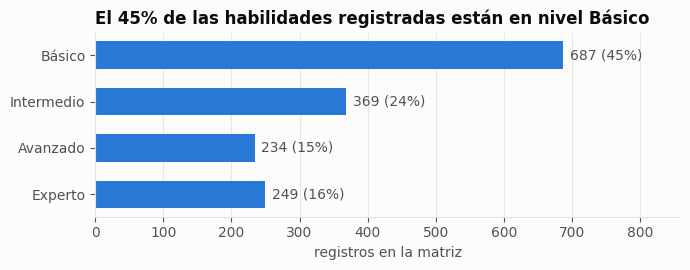

In [125]:
por_persona = mat.groupby('uid_colaborador').agg(habilidades=('codigo_habilidad', 'size'), niveles=('nivel', 'nunique'))
print('Habilidades por persona:', por_persona['habilidades'].describe().round(1).to_dict())
print('Personas con 60 o más habilidades:', (por_persona['habilidades'] >= 60).sum())
sospechosos = por_persona[(por_persona['niveles'] == 1) & (por_persona['habilidades'] > 20)].join(col.set_index('uid')[['id', 'puesto']])
print('Personas con más de 20 habilidades y TODAS en el mismo nivel (posible captura masiva):')
display(sospechosos)

orden = ['Básico', 'Intermedio', 'Avanzado', 'Experto']
niveles = mat['nivel'].value_counts().reindex(orden)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(niveles.index[::-1], niveles.values[::-1], color=AZUL, height=0.6)
for y, v in enumerate(niveles.values[::-1]):
    ax.text(v + 10, y, f'{v:,} ({v / niveles.sum():.0%})', va='center', color=TINTA2)
ax.set_title('El 45% de las habilidades registradas están en nivel Básico')
ax.set_xlabel('registros en la matriz'); ax.grid(axis='x', color=GRIS, lw=0.6); ax.set_axisbelow(True)
ax.set_xlim(0, niveles.max() * 1.25)
plt.tight_layout(); plt.show()

In [126]:
# ¿Qué habilidades dependen de una sola persona?
fuertes = m2[(m2['estatus'] == 'Activo') & m2['nivel'].isin(['Avanzado', 'Experto'])]
cobertura = fuertes.groupby('codigo_habilidad')['uid_colaborador'].nunique().reindex(hab['codigo'], fill_value=0)
criticas = hab.set_index('codigo').loc[cobertura[cobertura <= 1].index, ['descripcion', 'tecnologia']]
criticas['personas activas avanzado/experto'] = cobertura[cobertura <= 1]
print(f'Habilidades con 0 o 1 persona activa en nivel avanzado/experto: {len(criticas)}')
criticas

Habilidades con 0 o 1 persona activa en nivel avanzado/experto: 11


,descripcion,tecnologia,personas activas avanzado/experto
codigo,,,
H0007,XTR,Oracle eBS,1
H0008,eBTAX,Oracle eBS,1
H0023,OPM,Oracle eBS,0
H0028,TALEO,Oracle eBS,0
H0043,Landed Cost,Oracle Fusion Cloud,1
H0045,MFG,Oracle Fusion Cloud,1
H0049,OBI,Plataformas Tecnológicas,0
H0050,OCI,Plataformas Tecnológicas,1
H0062,FUSE,Plataformas Tecnológicas,0


**Hallazgos de habilidades**

- **71 habilidades en el catálogo** (67 técnicas y 4 blandas): 30 de Oracle EBS, 17 de Oracle Fusion Cloud, 20 de plataformas, más idiomas, certificación y 2 blandas. Todas están activas.
- **La descripción no es única:** 26 habilidades se repiten (por ejemplo, GL existe en EBS y en Cloud). Por eso siempre hay que usar el `codigo`, nunca el nombre. Además, H0068 "Oracle EBS" es una habilidad genérica que se empalma con los 29 módulos específicos de EBS.
- **La matriz tiene 1,539 registros de 56 personas**, con dos problemas de integridad: **2 `uid` que no existen en colaboradores** (registros huérfanos) y **7 personas dadas de baja** que siguen apareciendo.
- **28 de los 75 activos (37%) no tienen ninguna habilidad registrada**, así que no se les podría buscar por habilidad.
- **Captura poco confiable:** 7 personas tienen 60 o más habilidades y 2 tienen todas sus habilidades en el mismo nivel (por ejemplo, una gerente con 68 habilidades, todas en Básico). Eso apunta a que se "palomeó todo" en lugar de evaluar. Tampoco existe la **fecha de la última evaluación**, aunque OT dijo que evalúa cada 6 meses.
- **11 habilidades dependen de una persona o de nadie** en nivel avanzado/experto. Es un riesgo de negocio: si esa persona sale o está asignada, no hay quien la cubra.

### 3.4 `clientes.csv` y `proyectos.csv` · con quién y en qué se trabaja

In [127]:
cli = df['clientes']
display(perfil(cli.drop(columns=['contacto_email', 'contacto_nom', 'rfc'])))
print('País:', contar(cli['pais']).set_index('valor')['registros'].to_dict())
print('Industria:', contar(cli['industria'].str.strip()).set_index('valor')['registros'].to_dict())

,columna,tipo,nulos,% nulos,relleno,distintos,con espacios extra,ejemplo
0,pais,texto,4,50.0,0,4,2,"México, Méxcio , Mèxico"
1,estado,texto,4,50.0,0,2,3,"Nuevo León, Nuevo León"
2,direccion,número,8,100.0,0,0,0,
3,codigo,texto,0,0.0,0,8,0,"C0001, C0002, C0003"
4,estatus,texto,0,0.0,0,1,0,Activo
5,ciudad,texto,4,50.0,0,2,1,"Apodaca, El Carmen"
6,uid,texto,0,0.0,0,8,0,"1790111580747, 1790169945253, 1790170098418"
7,telefono,número,8,100.0,0,0,0,
8,contacto_tel,número,8,100.0,0,0,0,
9,nombre,texto,0,0.0,0,8,2,"METALSA, Grupo Daltile , Allegion"


País: {nan: 4, 'México': 1, 'Méxcio ': 1, 'Mèxico': 1, 'México ': 1}
Industria: {'Manufactura': 5, 'Automotriz': 1, 'Consultoría': 1, 'Rentas de equipo': 1}


In [128]:
pro = df['proyectos']
display(perfil(pro.drop(columns=['email_cli', 'resp_cli', 'tel_cli'])))
pro['inicio_d'] = pd.to_datetime(pro['inicio'], errors='coerce')
pro['fin_d'] = pd.to_datetime(pro['fin'], errors='coerce')
display(pro[['cliente', 'nombre', 'inicio', 'fin', 'estatus', 'pm_otc']])
print('Proyectos "En Curso" con fecha de fin ya vencida:',
      pro.loc[(pro['estatus'] == 'En Curso') & (pro['fin_d'] < FECHA_CORTE), 'nombre'].tolist())
print('¿Existe un campo de monto, horas, tarifa o tipo de proyecto?:',
      any(c in pro.columns for c in ['monto', 'horas', 'tarifa', 'tipo']))

,columna,tipo,nulos,% nulos,relleno,distintos,con espacios extra,ejemplo
0,uid_cliente,texto,0,0.0,0,8,0,"1790111580747, 1790169945253, 1790170098418"
1,cliente,texto,0,0.0,0,8,4,"METALSA, Grupo Daltile , Allegion"
2,inicio,texto,6,50.0,0,6,0,"2026-07-15, 2026-10-13, 2025-06-01"
3,fin,texto,9,75.0,0,3,0,"2026-09-23, 2028-10-30, 2026-10-30"
4,estatus,texto,0,0.0,0,2,0,"En Curso, Por Iniciar"
5,nombre,texto,0,0.0,0,12,2,"AMS Manufactura, Soporte AMS Manufacta, Asignación inde"
6,pm_otc,texto,6,50.0,0,3,0,"JUAN JOSÉ CORONADO BRAVO, Juan José Coronado Bravo, Jos"


,cliente,nombre,inicio,fin,estatus,pm_otc
0,METALSA,AMS Manufactura,NaN,NaN,En Curso,NaN
1,METALSA,Soporte AMS Manufacta,NaN,NaN,En Curso,NaN
2,METALSA,Asignación indefinida,NaN,NaN,Por Iniciar,NaN
3,Grupo Daltile,Marazzi,2026-07-15,2026-09-23,En Curso,NaN
4,Grupo Daltile,Asignación EBS temporal (3 meses),NaN,NaN,Por Iniciar,JUAN JOSÉ CORONADO BRAVO
5,Grupo Daltile,Asignación Funcional-Técnico (4 meses),NaN,NaN,Por Iniciar,JUAN JOSÉ CORONADO BRAVO
6,Allegion,Migración eBs,2026-10-13,2028-10-30,En Curso,NaN
7,CITI,Soporte Oracle Cloud,2025-06-01,NaN,En Curso,Juan José Coronado Bravo
8,Parker Servicios de México,Desarrollo de Indicadores,NaN,NaN,Por Iniciar,NaN
9,Rent A Center (RAC Mèxico Operaciones),SHINE - Asiganci´ñon de recursos de apoyo,2026-06-30,2026-10-30,En Curso,Juan José Coronado Bravo


Proyectos "En Curso" con fecha de fin ya vencida: ['Marazzi', 'SHINE - Asiganci´ñon de recursos de apoyo']
¿Existe un campo de monto, horas, tarifa o tipo de proyecto?: False


**Hallazgos de clientes y proyectos**

- **8 clientes**, todos activos. Faltan datos básicos: 4 sin país (y 3 con el país mal escrito: "Méxcio", "Mèxico", "México "), 4 sin RFC, y los 8 sin dirección ni teléfono. Varios nombres traen espacios de más ("Grupo Daltile ").
- **12 proyectos, sin un identificador propio.** El proyecto solo se reconoce por *cliente + nombre*. Eso es frágil: "Migración eBs " con un espacio al final es otro proyecto para la computadora.
- **No existe ningún dato económico:** ni monto vendido, ni horas, ni tarifa, ni tipo de proyecto. **Con esta tabla es imposible calcular el margen**, que es la tercera necesidad del director.
- **El tipo se escribe en el nombre:** "Asignación indefinida" o "Asignación EBS temporal (3 meses)" aparecen como nombres de proyecto.
- **Fechas y estatus incompletos o contradictorios:** 6 proyectos sin fecha de inicio y 9 sin fecha de fin. Marazzi y SHINE siguen "En Curso" con su fecha de fin ya vencida.
- **El gerente de OT (`pm_otc`) falta en 6 proyectos** y se escribe como texto libre ("JUAN JOSÉ CORONADO BRAVO" y "Juan José Coronado Bravo"), sin ligarse a la tabla de colaboradores.

### 3.5 `asignaciones.csv` · quién está en qué proyecto

Esta tabla es la que conecta a la gente con los proyectos. Sin ella no se puede saber quién está en la banca.

In [129]:
asg = df['asignaciones'].copy()
asg[['uid_cliente', 'proyecto']] = asg['proyecto_val'].str.split('|', n=1, expand=True)
display(perfil(asg))
print('Rol asignado:', contar(asg['rol']).set_index('valor')['registros'].to_dict())
print('Inicio con fecha de relleno 1990-01-01:', (asg['inicio'] == '1990-01-01').sum(), 'de', len(asg))
print('Sin fecha de fin:', asg['fin'].isna().sum(), 'de', len(asg))
print('Colaboradores distintos asignados:', asg['uid_colaborador'].nunique())
print('Asignaciones de colaboradores dados de baja:',
      asg['uid_colaborador'].map(col.set_index('uid')['estatus']).eq('Baja').sum())
print('\nTipo de asignación por proyecto (debería ser uno solo por proyecto):')
display(asg.groupby('proyecto')['tipo'].value_counts().unstack(fill_value=0))

,columna,tipo,nulos,% nulos,relleno,distintos,con espacios extra,ejemplo
0,uid_colaborador,texto,0,0.0,0,30,0,"1791239420562128, 1791239420735164, 1791239420884670"
1,rol,texto,0,0.0,29,2,0,"PENDIENTE, CONSULTOR FUNCIONAL ORACLE EBS SENIOR"
2,proyecto_val,texto,0,0.0,0,4,5,"1790111580747|Asignación indefinida, 1790111580747|Sopo"
3,tipo,texto,0,0.0,0,2,0,"Asignación, Proyecto"
4,inicio,texto,0,0.0,21,4,0,"1990-01-01, 2025-11-03, 2026-01-01"
5,fin,texto,24,77.4,0,3,0,"2027-01-01, 2027-07-01, 2028-07-01"
6,estatus,texto,0,0.0,0,1,0,En Curso
7,uid_cliente,texto,0,0.0,0,3,0,"1790111580747, 1790169945253, 1790170098418"
8,proyecto,texto,0,0.0,0,4,5,"Asignación indefinida, Soporte AMS Manufacta, Marazzi"


Rol asignado: {'PENDIENTE': 29, 'CONSULTOR FUNCIONAL ORACLE EBS SENIOR': 2}
Inicio con fecha de relleno 1990-01-01: 21 de 31
Sin fecha de fin: 24 de 31
Colaboradores distintos asignados: 30
Asignaciones de colaboradores dados de baja: 0

Tipo de asignación por proyecto (debería ser uno solo por proyecto):


tipo,Asignación,Proyecto
proyecto,,
Asignación indefinida,13,5
Marazzi,0,3
Migración eBs,0,5
Soporte AMS Manufacta,2,3


In [130]:
# ¿Las fechas de la asignación caen dentro de las fechas del proyecto?
x = asg.merge(pro, left_on=['uid_cliente', 'proyecto'], right_on=['uid_cliente', 'nombre'], how='left', suffixes=('', '_pro'))
x['inicio_a'] = pd.to_datetime(x['inicio'], errors='coerce'); x['fin_a'] = pd.to_datetime(x['fin'], errors='coerce')
fuera = x[(x['inicio_a'] < x['inicio_d']) | (x['fin_a'] > x['fin_d'])]
print('Asignaciones fuera del periodo del proyecto:', len(fuera))
display(fuera[['proyecto', 'inicio', 'fin', 'inicio_pro', 'fin_pro']].drop_duplicates())
print('Asignaciones "En Curso" en un proyecto "Por Iniciar":',
      ((x['estatus'] == 'En Curso') & (x['estatus_pro'] == 'Por Iniciar')).sum())
print('¿Existe un campo de horas, % de dedicación o tarifa?:',
      any(c in asg.columns for c in ['horas', 'dedicacion', 'tarifa']))

Asignaciones fuera del periodo del proyecto: 3


,proyecto,inicio,fin,inicio_pro,fin_pro
4,Marazzi,2026-01-01,2027-01-01,2026-07-15,2026-09-23


Asignaciones "En Curso" en un proyecto "Por Iniciar": 18
¿Existe un campo de horas, % de dedicación o tarifa?: False


**Hallazgos de asignaciones**

- **31 asignaciones de 30 personas.** Solo una persona (la gerente de proyectos) está en dos proyectos, lo que cuadra con la regla de OT de que un consultor normalmente va a un solo proyecto.
- **El rol dentro del proyecto está en `PENDIENTE` en 29 de 31 (94%).** No se sabe qué papel juega cada quien, y sin el rol no se le puede poner una tarifa.
- **21 de 31 inician el 1990-01-01** (fecha de relleno) y **24 no tienen fecha de fin.** Con eso no se puede responder "¿quién se libera pronto?" para la mayoría.
- **El tipo es inconsistente dentro del mismo proyecto:** en "Asignación indefinida" hay 13 marcadas como *Asignación* y 5 como *Proyecto*.
- **Contradicciones con el proyecto:** las 3 asignaciones de Marazzi (ene 2026–ene 2027) caen fuera del periodo del proyecto (jul–sep 2026), y hay 18 asignaciones "En Curso" en un proyecto que dice "Por Iniciar".
- **Lo bueno:** ninguna asignación apunta a un colaborador de baja ni a un proyecto inexistente.
- **Falta lo esencial para el margen:** no hay horas, porcentaje de dedicación ni tarifa de venta.

### 3.6 `activos.csv`, `activos_asignaciones.csv` y `usuarios.csv`

No son el centro del reto, pero completan la foto de la calidad de datos de la app.

In [131]:
act = df['activos']
display(perfil(act))
print('Tipo:', contar(act['tipo']).set_index('valor')['registros'].to_dict())
print('Marcas tal como se capturaron:', act['marca'].nunique(), '→ normalizadas:', act['marca'].str.strip().str.upper().nunique())
print('Costo en 0:', (act['costo'] == 0).sum(), '| Sin fecha de compra:', act['fcompra'].isna().sum(),
      '| Sin garantía:', act['fgarantia'].isna().sum(), '| Sin asignar:', (act['n_asig'] == 0).sum())

,columna,tipo,nulos,% nulos,relleno,distintos,con espacios extra,ejemplo
0,codigo,texto,0,0.0,0,123,0,"A0001, A0002, A0003"
1,tipo,texto,0,0.0,0,2,0,"Laptop, Monitor"
2,marca,texto,0,0.0,0,12,10,"LENOVO, HP, DELL"
3,modelo,texto,1,0.8,0,78,6,"V14 G2 ALC, 245 G8 Notebook, Latitude 5490"
4,estatus,texto,0,0.0,0,1,0,Activo
5,costo,número,0,0.0,0,31,0,"7999.0, 8999.0, 0.0"
6,esquema,texto,0,0.0,0,1,0,Unidad
7,uom,texto,0,0.0,0,1,0,Pieza
8,fcompra,texto,70,56.9,0,35,0,"2023-04-25, 2023-03-27, 2024-05-21"
9,fgarantia,número,123,100.0,0,0,0,


Tipo: {'Laptop': 122, 'Monitor': 1}
Marcas tal como se capturaron: 12 → normalizadas: 5
Costo en 0: 70 | Sin fecha de compra: 70 | Sin garantía: 123 | Sin asignar: 32


In [132]:
aa = df['activos_asignaciones'].merge(col[['uid', 'id', 'estatus']], left_on='uid_colab', right_on='uid', how='left')
vigentes = aa[aa['f_fin'].isna()]
print('Asignaciones de equipo con inicio 1990-01-01:', (aa['f_ini'] == '1990-01-01').sum())
print('Fechas imposibles:', aa.loc[~aa['f_ini'].str.match(r'^(19|20)\d{2}-'), ['codigo_activo', 'f_ini']].values.tolist())
print('Equipos vigentes en manos de colaboradores dados de baja:', len(vigentes[vigentes['estatus'] == 'Baja']))
print(vigentes.loc[vigentes['estatus'] == 'Baja', ['codigo_activo', 'id']].values.tolist())
print('Personas con más de un equipo vigente:', vigentes.groupby('uid_colab').size().gt(1).sum())

usu = df['usuarios']
print('\nUsuarios de la app:', len(usu), '| Roles:', contar(usu['rol']).set_index('valor')['registros'].to_dict())

Asignaciones de equipo con inicio 1990-01-01: 35
Fechas imposibles: [['A0075', '0199-01-01']]
Equipos vigentes en manos de colaboradores dados de baja: 9
[['A0010', 'OTC018'], ['A0026', 'OTC048'], ['A0030', 'OTC054'], ['A0034', 'OTC053'], ['A0047', 'OTC070'], ['A0059', 'OTC093'], ['A0071', 'OTC020'], ['A0090', 'OTC072'], ['A0100', 'OTC008']]
Personas con más de un equipo vigente: 15

Usuarios de la app: 6 | Roles: {'Administrador': 6}


**Hallazgos de activos y usuarios**

- **123 activos** (122 laptops y 1 monitor). El 57% tiene **costo en 0 y sin fecha de compra**, y **ninguno tiene garantía**. Así no se puede valuar el inventario.
- **La marca se escribe de 12 formas para 5 marcas** ("DELL", "Dell", "DELL ").
- **9 equipos siguen asignados a personas dadas de baja**, sin fecha de devolución. Es un posible equipo no recuperado.
- **Las asignaciones de equipo usan 1990-01-01 como fecha de relleno** (35 casos) y hay una fecha imposible (0199-01-01).
- **Los 6 usuarios de la app son Administrador** (los 5 equipos y la profesora). Además, durante la extracción vi que la colección de usuarios guarda la contraseña como un campo más del registro. No la extraje, pero es un riesgo de seguridad que conviene reportar al socio.

## 4. Integridad entre tablas (con SQL)

Cargo las tablas en una base SQLite en memoria para revisar con consultas SQL que las relaciones entre tablas se cumplan.

In [133]:
con = sqlite3.connect(':memory:')
for nombre, tabla in df.items():
    tabla.drop(columns=[c for c in tabla.columns if c.endswith('_d')], errors='ignore').to_sql(nombre, con, index=False)

def sql(q):
    return pd.read_sql_query(q, con)

sql('''
SELECT 'matriz → colaboradores' AS relacion, COUNT(DISTINCT m.uid_colaborador) AS sin_pareja
  FROM matriz_habilidades m LEFT JOIN colaboradores c ON c.uid = m.uid_colaborador WHERE c.uid IS NULL
UNION ALL
SELECT 'matriz → habilidades', COUNT(*) FROM matriz_habilidades m
  LEFT JOIN habilidades h ON h.codigo = m.codigo_habilidad WHERE h.codigo IS NULL
UNION ALL
SELECT 'asignaciones → colaboradores', COUNT(*) FROM asignaciones a
  LEFT JOIN colaboradores c ON c.uid = a.uid_colaborador WHERE c.uid IS NULL
UNION ALL
SELECT 'asignaciones → proyectos', COUNT(*) FROM asignaciones a
  LEFT JOIN proyectos p ON a.proyecto_val = p.uid_cliente || '|' || p.nombre WHERE p.nombre IS NULL
UNION ALL
SELECT 'colaboradores.puesto → roles', COUNT(*) FROM colaboradores c
  LEFT JOIN roles r ON r.nombre = c.puesto WHERE r.nombre IS NULL
UNION ALL
SELECT 'proyectos.pm_otc → colaboradores', COUNT(*) FROM proyectos p
  LEFT JOIN colaboradores c ON UPPER(c.nombre) = UPPER(p.pm_otc) WHERE p.pm_otc IS NOT NULL AND c.uid IS NULL
UNION ALL
SELECT 'equipo vigente → colaborador activo', COUNT(*) FROM activos_asignaciones x
  JOIN colaboradores c ON c.uid = x.uid_colab WHERE x.f_fin IS NULL AND c.estatus = 'Baja'
''')

,relacion,sin_pareja
0,matriz → colaboradores,2
1,matriz → habilidades,0
2,asignaciones → colaboradores,0
3,asignaciones → proyectos,0
4,colaboradores.puesto → roles,0
5,proyectos.pm_otc → colaboradores,6
6,equipo vigente → colaborador activo,9


In [134]:
# ¿Cuánta nómina mensual de activos está asignada a un proyecto y cuánta no?
sql('''
SELECT CASE WHEN a.uid_colaborador IS NULL THEN 'Sin asignación' ELSE 'Con asignación' END AS situacion,
       COUNT(*) AS personas,
       ROUND(SUM(c.sueldo_total_integrado), 0) AS costo_mensual
  FROM colaboradores c
  LEFT JOIN (SELECT DISTINCT uid_colaborador FROM asignaciones WHERE estatus = 'En Curso') a
         ON a.uid_colaborador = c.uid
 WHERE c.estatus = 'Activo'
 GROUP BY 1
''')

,situacion,personas,costo_mensual
0,Con asignación,30,1924711.0
1,Sin asignación,45,1994154.0


**Hallazgos de integridad**

- Las relaciones *asignación → colaborador*, *asignación → proyecto* y *puesto → rol* se cumplen al 100%, pero **solo porque se ligan por texto** (nombre del puesto, nombre del proyecto). Funciona hoy, pero se rompe en cuanto alguien corrige un nombre.
- **2 colaboradores fantasma en la matriz** (uid sin colaborador) y **9 equipos vigentes en manos de bajas**.
- **El gerente de proyecto no se puede ligar** a ningún colaborador: está escrito a mano.
- **La mitad de la nómina de activos aparece "sin asignación"** (45 personas). Pero no hay que leerlo como banca real: incluye personal administrativo, familiares y consultores a quienes simplemente no se les capturó la asignación. Primero hay que limpiar los datos para poder medir la banca de verdad.

## 5. Resumen de errores, faltantes e inconsistencias

Junto todos los hallazgos en una sola tabla para que se puedan ordenar por gravedad.

In [135]:
A = activos
hallazgos = [
    # tabla, campo, tipo, afectados, total
    ('colaboradores', 'puesto = PENDIENTE (activos)', 'Faltante', (A['puesto'] == 'PENDIENTE').sum(), len(A)),
    ('colaboradores', 'depto vacío (activos)', 'Faltante', A['depto'].isna().sum(), len(A)),
    ('colaboradores', 'baja sin fecha de baja', 'Inconsistencia', ((col['estatus'] == 'Baja') & col['fechabaja'].isna()).sum(), (col['estatus'] == 'Baja').sum()),
    ('colaboradores', 'baja con sueldo capturado', 'Inconsistencia', ((col['estatus'] == 'Baja') & (col['sueldo_total_integrado'] > 0)).sum(), (col['estatus'] == 'Baja').sum()),
    ('colaboradores', 'activo con costo en 0', 'Faltante', (A['sueldo_total_integrado'] == 0).sum(), len(A)),
    ('colaboradores', 'familiar registrado como colaborador', 'Estructura', (col['puesto'] == 'FAMILIAR COLABORADOR').sum(), len(col)),
    ('colaboradores', 'activo sin habilidades en la matriz', 'Faltante', (~A['uid'].isin(mat['uid_colaborador'])).sum(), len(A)),
    ('matriz', 'uid sin colaborador (huérfano)', 'Error', len(huerfanos), mat['uid_colaborador'].nunique()),
    ('matriz', 'colaborador de baja en la matriz', 'Inconsistencia', m2.loc[m2['estatus'] == 'Baja', 'uid_colaborador'].nunique(), mat['uid_colaborador'].nunique()),
    ('roles', 'descripción = nombre', 'Estructura', int(roles['desc_igual_nombre'].sum()), len(roles)),
    ('departamentos', 'sin responsable ni centro de costos', 'Faltante', dep['responsable'].isna().sum(), len(dep)),
    ('clientes', 'sin RFC', 'Faltante', cli['rfc'].isna().sum(), len(cli)),
    ('proyectos', 'sin fecha de inicio', 'Faltante', pro['inicio'].isna().sum(), len(pro)),
    ('proyectos', 'sin fecha de fin', 'Faltante', pro['fin'].isna().sum(), len(pro)),
    ('proyectos', 'sin gerente OT', 'Faltante', pro['pm_otc'].isna().sum(), len(pro)),
    ('proyectos', 'sin monto, horas ni tarifa', 'Estructura', len(pro), len(pro)),
    ('asignaciones', 'rol = PENDIENTE', 'Faltante', (asg['rol'] == 'PENDIENTE').sum(), len(asg)),
    ('asignaciones', 'inicio de relleno 1990-01-01', 'Error', (asg['inicio'] == '1990-01-01').sum(), len(asg)),
    ('asignaciones', 'sin fecha de fin', 'Faltante', asg['fin'].isna().sum(), len(asg)),
    ('asignaciones', 'fuera del periodo del proyecto', 'Inconsistencia', len(fuera), len(asg)),
    ('asignaciones', 'sin horas, % ni tarifa', 'Estructura', len(asg), len(asg)),
    ('activos', 'costo en 0', 'Faltante', (act['costo'] == 0).sum(), len(act)),
    ('activos', 'sin garantía', 'Faltante', act['fgarantia'].isna().sum(), len(act)),
    ('activos_asignaciones', 'equipo vigente con colaborador de baja', 'Inconsistencia', len(vigentes[vigentes['estatus'] == 'Baja']), len(vigentes)),
    ('usuarios', 'todos con rol Administrador', 'Estructura', (usu['rol'] == 'Administrador').sum(), len(usu)),
]
resumen_errores = pd.DataFrame(hallazgos, columns=['tabla', 'problema', 'tipo', 'afectados', 'total'])
resumen_errores['%'] = (resumen_errores['afectados'] / resumen_errores['total'] * 100).round(0)
resumen_errores = resumen_errores.sort_values('%', ascending=False).reset_index(drop=True)
resumen_errores.to_csv('hallazgos_calidad.csv', index=False)
resumen_errores

,tabla,problema,tipo,afectados,total,%
0,departamentos,sin responsable ni centro de costos,Faltante,6,6,100.0
1,asignaciones,"sin horas, % ni tarifa",Estructura,31,31,100.0
2,activos,sin garantía,Faltante,123,123,100.0
3,proyectos,"sin monto, horas ni tarifa",Estructura,12,12,100.0
4,usuarios,todos con rol Administrador,Estructura,6,6,100.0
5,roles,descripción = nombre,Estructura,54,55,98.0
6,asignaciones,rol = PENDIENTE,Faltante,29,31,94.0
7,colaboradores,depto vacío (activos),Faltante,64,75,85.0
8,asignaciones,sin fecha de fin,Faltante,24,31,77.0
9,proyectos,sin fecha de fin,Faltante,9,12,75.0


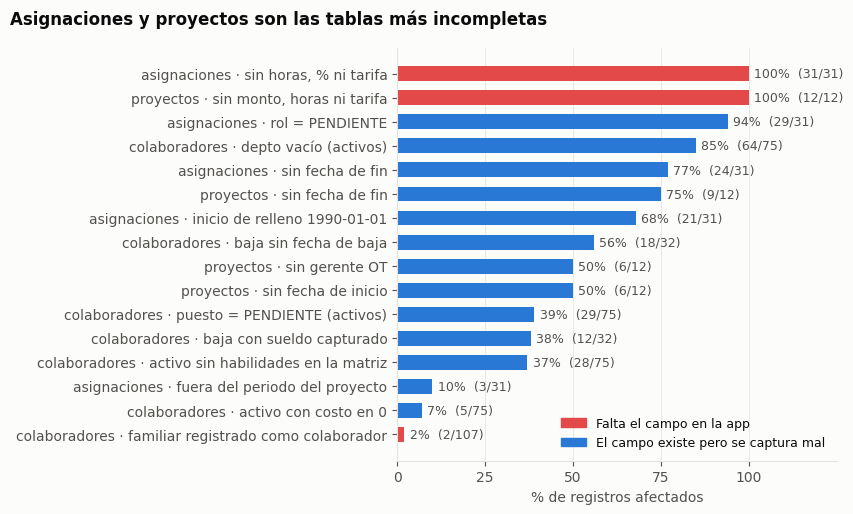

In [136]:
clave = resumen_errores[resumen_errores['tabla'].isin(['colaboradores', 'asignaciones', 'proyectos'])].copy()
clave['etiqueta'] = clave['tabla'] + ' · ' + clave['problema']
clave = clave.sort_values('%')
fig, ax = plt.subplots(figsize=(8.5, 5.2))
colores = [ROJO if t == 'Estructura' else AZUL for t in clave['tipo']]
ax.barh(clave['etiqueta'], clave['%'], color=colores, height=0.62)
for y, (v, n, t) in enumerate(zip(clave['%'], clave['afectados'], clave['total'])):
    ax.text(v + 1.5, y, f'{v:.0f}%  ({n}/{t})', va='center', color=TINTA2, fontsize=9)
ax.set_xlim(0, 125); ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel('% de registros afectados'); ax.grid(axis='x', color=GRIS, lw=0.6); ax.set_axisbelow(True)
fig.suptitle('Asignaciones y proyectos son las tablas más incompletas', x=0.01, ha='left', fontweight='bold', fontsize=12)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ROJO, label='Falta el campo en la app'), Patch(color=AZUL, label='El campo existe pero se captura mal')],
          loc='lower right', frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig('grafica_calidad.png', dpi=160); plt.show()

**Lectura del resumen:** los problemas más graves no son de "dedo" sino de **estructura**. Los campos para calcular el margen (monto, horas y tarifa) no existen. Y los que sí existen, como el rol, las fechas y el departamento, se pueden dejar en `PENDIENTE` o con fechas de relleno porque la app no valida la captura.

## 6. Modelo de datos sugerido con los errores marcados

El diagrama muestra cómo deberían relacionarse las tablas: por código, no por nombre. En **naranja** van los campos que proponemos agregar y en **rojo** los errores encontrados en cada tabla.

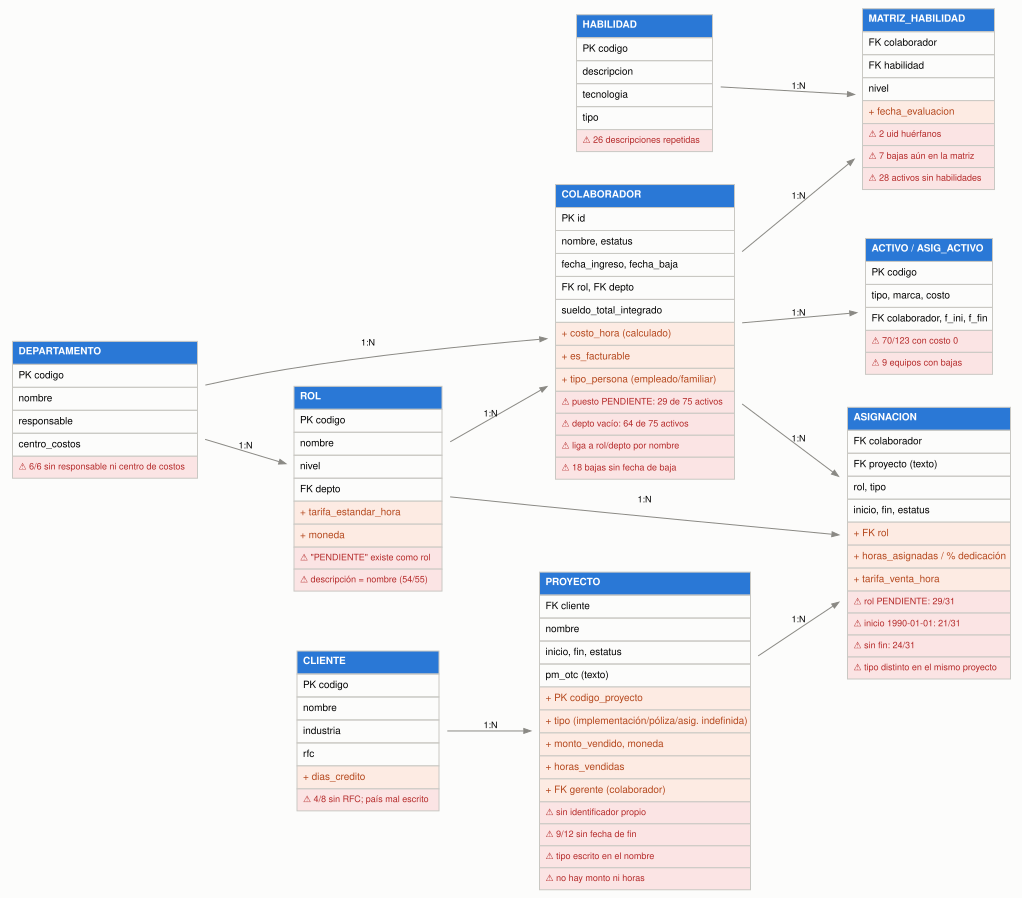

In [137]:
try:
    import graphviz
except ImportError:
    !pip -q install graphviz
    import graphviz

def tabla(nombre, campos, nuevos=(), errores=()):
    filas = [f'<TR><TD BGCOLOR="#2a78d6" ALIGN="LEFT"><FONT COLOR="white"><B>{nombre}</B></FONT></TD></TR>']
    filas += [f'<TR><TD ALIGN="LEFT">{c}</TD></TR>' for c in campos]
    filas += [f'<TR><TD ALIGN="LEFT" BGCOLOR="#fdebe3"><FONT COLOR="#b4461b">+ {c}</FONT></TD></TR>' for c in nuevos]
    filas += [f'<TR><TD ALIGN="LEFT" BGCOLOR="#fbe4e4"><FONT COLOR="#b42828" POINT-SIZE="9">⚠ {e}</FONT></TD></TR>' for e in errores]
    return '<<TABLE BORDER="0" CELLBORDER="1" CELLSPACING="0" CELLPADDING="5" COLOR="#c9c8c3">' + ''.join(filas) + '</TABLE>>'

g = graphviz.Digraph('modelo', graph_attr={'rankdir': 'LR', 'bgcolor': '#fcfcfb', 'nodesep': '0.35', 'ranksep': '0.9', 'fontname': 'Helvetica'},
                     node_attr={'shape': 'plaintext', 'fontname': 'Helvetica', 'fontsize': '10'},
                     edge_attr={'color': '#8a8984', 'fontname': 'Helvetica', 'fontsize': '9', 'arrowsize': '0.7'})
g.node('dep', tabla('DEPARTAMENTO', ['PK codigo', 'nombre', 'responsable', 'centro_costos'], errores=['6/6 sin responsable ni centro de costos']))
g.node('rol', tabla('ROL', ['PK codigo', 'nombre', 'nivel', 'FK depto'], nuevos=['tarifa_estandar_hora', 'moneda'], errores=['"PENDIENTE" existe como rol', 'descripción = nombre (54/55)']))
g.node('col', tabla('COLABORADOR', ['PK id', 'nombre, estatus', 'fecha_ingreso, fecha_baja', 'FK rol, FK depto', 'sueldo_total_integrado'],
                    nuevos=['costo_hora (calculado)', 'es_facturable', 'tipo_persona (empleado/familiar)'],
                    errores=['puesto PENDIENTE: 29 de 75 activos', 'depto vacío: 64 de 75 activos', 'liga a rol/depto por nombre', '18 bajas sin fecha de baja']))
g.node('hab', tabla('HABILIDAD', ['PK codigo', 'descripcion', 'tecnologia', 'tipo'], errores=['26 descripciones repetidas']))
g.node('mat', tabla('MATRIZ_HABILIDAD', ['FK colaborador', 'FK habilidad', 'nivel'], nuevos=['fecha_evaluacion'],
                    errores=['2 uid huérfanos', '7 bajas aún en la matriz', '28 activos sin habilidades']))
g.node('cli', tabla('CLIENTE', ['PK codigo', 'nombre', 'industria', 'rfc'], nuevos=['dias_credito'], errores=['4/8 sin RFC; país mal escrito']))
g.node('pro', tabla('PROYECTO', ['FK cliente', 'nombre', 'inicio, fin, estatus', 'pm_otc (texto)'],
                    nuevos=['PK codigo_proyecto', 'tipo (implementación/póliza/asig. indefinida)', 'monto_vendido, moneda', 'horas_vendidas', 'FK gerente (colaborador)'],
                    errores=['sin identificador propio', '9/12 sin fecha de fin', 'tipo escrito en el nombre', 'no hay monto ni horas']))
g.node('asg', tabla('ASIGNACION', ['FK colaborador', 'FK proyecto (texto)', 'rol, tipo', 'inicio, fin, estatus'],
                    nuevos=['FK rol', 'horas_asignadas / % dedicación', 'tarifa_venta_hora'],
                    errores=['rol PENDIENTE: 29/31', 'inicio 1990-01-01: 21/31', 'sin fin: 24/31', 'tipo distinto en el mismo proyecto']))
g.node('act', tabla('ACTIVO / ASIG_ACTIVO', ['PK codigo', 'tipo, marca, costo', 'FK colaborador, f_ini, f_fin'],
                    errores=['70/123 con costo 0', '9 equipos con bajas']))
for a, b, l in [('dep', 'rol', '1:N'), ('dep', 'col', '1:N'), ('rol', 'col', '1:N'), ('col', 'mat', '1:N'), ('hab', 'mat', '1:N'),
                ('cli', 'pro', '1:N'), ('pro', 'asg', '1:N'), ('col', 'asg', '1:N'), ('rol', 'asg', '1:N'), ('col', 'act', '1:N')]:
    g.edge(a, b, label=l)
g.render('modelo_sugerido', format='png', cleanup=True)
g

**Cambios clave del modelo sugerido**

1. **El proyecto se vuelve una tabla propia** con código, tipo, monto, horas vendidas y gerente (ligado a colaborador).
2. **La asignación guarda horas o % de dedicación, el rol (por código) y la tarifa.** Con eso, *horas × tarifa* da el ingreso y *horas × costo por hora* da el costo, y la diferencia es el margen.
3. **Todas las relaciones van por código**, no por nombre.
4. **El rol tiene una tarifa estándar** para estimar ingresos aunque la asignación no traiga una tarifa negociada.
5. **El colaborador distingue si es facturable** (consultor) o no (administrativo o familiar), para medir la banca solo sobre quien debería estar facturando.

## 7. ¿Qué se puede medir hoy y qué no?

Pruebo si con los datos actuales se pueden calcular las métricas que pidió el director. **No respondo todavía las preguntas de análisis**; solo verifico si el dato existe y qué tan confiable es.

Costo por hora (MXN) de 70 activos con costo: mediana 359, mín 51, máx 924


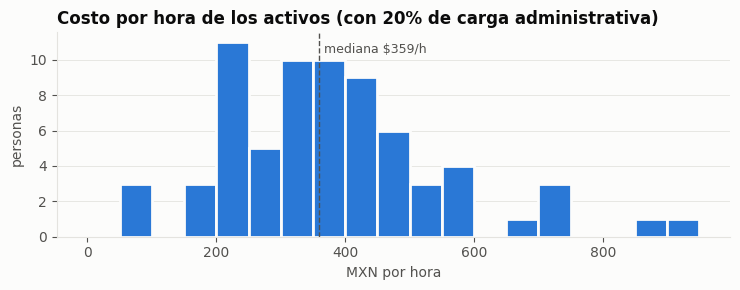

In [138]:
A = activos.copy()
A['costo_hora'] = A['sueldo_total_integrado'] * (1 + CARGA_ADMIN) / HORAS_MES
con_costo = A[A['sueldo_total_integrado'] > 0]
print(f"Costo por hora (MXN) de {len(con_costo)} activos con costo: "
      f"mediana {con_costo['costo_hora'].median():,.0f}, mín {con_costo['costo_hora'].min():,.0f}, máx {con_costo['costo_hora'].max():,.0f}")

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.hist(con_costo['costo_hora'], bins=range(0, 1000, 50), color=AZUL, edgecolor=FONDO, linewidth=2)
ax.axvline(con_costo['costo_hora'].median(), color=TINTA2, ls='--', lw=1)
ax.text(con_costo['costo_hora'].median() + 8, ax.get_ylim()[1] * 0.9, f"mediana ${con_costo['costo_hora'].median():,.0f}/h", color=TINTA2, fontsize=9)
ax.set_title('Costo por hora de los activos (con 20% de carga administrativa)')
ax.set_xlabel('MXN por hora'); ax.set_ylabel('personas'); ax.grid(axis='y', color=GRIS, lw=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [139]:
asignados = set(asg.loc[asg['estatus'] == 'En Curso', 'uid_colaborador'])
asg['fin_d'] = pd.to_datetime(asg['fin'], errors='coerce')
se_liberan = asg[(asg['fin_d'] >= FECHA_CORTE) & (asg['fin_d'] <= FECHA_CORTE + pd.Timedelta(days=90))]

factibilidad = pd.DataFrame([
    ['Costo por hora de cada consultor', 'Sí', f"{len(con_costo)} de {len(A)} activos tienen costo", '5 activos con costo en 0'],
    ['Consultores en la banca', 'A medias', f"{(~A['uid'].isin(asignados)).sum()} activos sin asignación", 'No se distingue facturable vs administrativo; asignaciones sin capturar'],
    ['Quién se libera en 30/60/90 días', 'A medias', f"{len(se_liberan)} asignaciones terminan en 90 días", f"{asg['fin'].isna().sum()} de {len(asg)} asignaciones sin fecha de fin"],
    ['% de nómina asignada', 'A medias', f"{A.loc[A['uid'].isin(asignados), 'sueldo_total_integrado'].sum() / A['sueldo_total_integrado'].sum():.0%} asignada", 'Falta % de dedicación; asume 100%'],
    ['Consultores disponibles por habilidad', 'A medias', f"{A['uid'].isin(mat['uid_colaborador']).sum()} activos con matriz", '28 activos sin habilidades; captura masiva'],
    ['Margen esperado por proyecto', 'No', '—', 'No existe monto, horas ni tarifa'],
    ['Top 10 consultores más rentables', 'No', '—', 'No existe tarifa ni horas facturables'],
    ['Facturación proyectada', 'No', '—', 'La facturación vive fuera de la app'],
], columns=['métrica que pidió el director', '¿se puede hoy?', 'lo que hay', 'lo que falta'])
factibilidad

,métrica que pidió el director,¿se puede hoy?,lo que hay,lo que falta
0,Costo por hora de cada consultor,Sí,70 de 75 activos tienen costo,5 activos con costo en 0
1,Consultores en la banca,A medias,45 activos sin asignación,No se distingue facturable vs administrativo; asignacion...
2,Quién se libera en 30/60/90 días,A medias,3 asignaciones terminan en 90 días,24 de 31 asignaciones sin fecha de fin
3,% de nómina asignada,A medias,49% asignada,Falta % de dedicación; asume 100%
4,Consultores disponibles por habilidad,A medias,47 activos con matriz,28 activos sin habilidades; captura masiva
5,Margen esperado por proyecto,No,—,"No existe monto, horas ni tarifa"
6,Top 10 consultores más rentables,No,—,No existe tarifa ni horas facturables
7,Facturación proyectada,No,—,La facturación vive fuera de la app


## 8. Conclusiones de la exploración

**¿Qué aprendí de los datos?**

1. **La app sí resuelve "quién es quién"** (personas, puestos estandarizados, habilidades y equipo) **pero no resuelve "cuánto deja"**. El costo de cada persona existe y sus fórmulas cuadran, pero el ingreso no existe en ningún lado.
2. **El mayor problema no son errores de captura aislados, sino que la app deja guardar datos incompletos.** `PENDIENTE` es un rol válido en el catálogo, las fechas aceptan 1990-01-01 y nada es obligatorio. Por eso el 94% de las asignaciones no tiene rol y el 85% de los activos no tiene departamento.
3. **Las tablas se ligan por texto.** Funciona con datos de ejemplo, pero con datos reales cualquier corrección de un nombre rompe las relaciones.
4. **Cualquier indicador de banca o de nómina asignada que se calcule hoy sale engañoso.** Mezcla consultores con administrativos y familiares, y depende de asignaciones que no están capturadas.

**¿Qué sigue (Etapa 3: preparación de los datos)?**

- Definir y aplicar las reglas de negocio de limpieza (sección de reglas del documento).
- Agregar los campos del modelo sugerido: código, tipo, monto y horas del proyecto, y horas o %, rol y tarifa de la asignación.
- Construir los indicadores sobre los datos ya limpios.